# Objective

## Dhaka regularly ranks among the most polluted cities in the world, and fine particulate matter (PM2.5) is the pollutant most closely linked to serious health risks for its residents. The objective of this project is to build a time series model that forecasts hourly PM2.5 concentrations in Dhaka for the next 24 to 72 hours, using recent air quality data and meteorological variables (temperature, humidity, wind speed, and precipitation) from the Open-Meteo APIs. The workflow covers data collection, cleaning, and exploratory analysis of daily and seasonal patterns, followed by a comparison of a seasonal naive baseline against statistical models (SARIMA, Prophet) and machine learning models (XGBoost, LightGBM) with lag and weather features. Models are evaluated with rolling-origin validation to avoid data leakage, and the best one is deployed as a live Streamlit app that refreshes automatically with the latest data, so anyone can see the current air quality and the upcoming forecast.

# Import Necessary Libraries

In [9]:
# Data collection and handling
import requests
import pandas as pd
import numpy as np
import time
from datetime import datetime, timedelta

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Time series analysis and statistical models
from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from prophet import Prophet

# Machine learning models and validation
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

# Saving the model for deployment
import joblib


# API feasibility Test

In [10]:
#Define the API URL
url = "https://air-quality-api.open-meteo.com/v1/air-quality"
params = {
    "latitude": 23.81,
    "longitude": 90.41,
    "hourly": "pm2_5",
    "start_date": "2022-10-01",
    "end_date": "2026-10-24",
    "timezone": "Asia/Dhaka",
}

# Fetch data from the API
response = requests.get(url, params=params, timeout=60)
response.raise_for_status()
data = response.json()



# Build DataFrame

In [13]:
hourly_data = data["hourly"]
df = pd.DataFrame({
    "time": hourly_data["time"],
    "pm2_5": hourly_data["pm2_5"],
})
df.head()
df = pd.read_csv("air_ql.csv").drop(columns="Unnamed: 0", errors="ignore")
df["time"] = pd.to_datetime(df["time"])
df.set_index("time")["pm2_5"].asfreq("h").to_csv("pm25_history.csv")

## Set data formats

In [8]:
df=pd.read_csv("air_ql.csv")
df = df.drop(columns="Unnamed: 0")
df['time']=pd.to_datetime(df["time"])
df=df.set_index('time')
# Basic checks
print(df.shape)
print(df.index.min(), "->", df.index.max())
print("Frequency:", pd.infer_freq(df.index))
print("Null Values",df.isna().sum())
print(df.describe())

(35640, 1)
2022-10-01 00:00:00 -> 2026-10-24 23:00:00
Frequency: h
Null Values pm2_5    0
dtype: int64
              pm2_5
count  35640.000000
mean      48.565014
std       34.246410
min        0.400000
25%       22.300000
50%       41.200000
75%       66.600000
max      309.200000


# Explore the Dataset

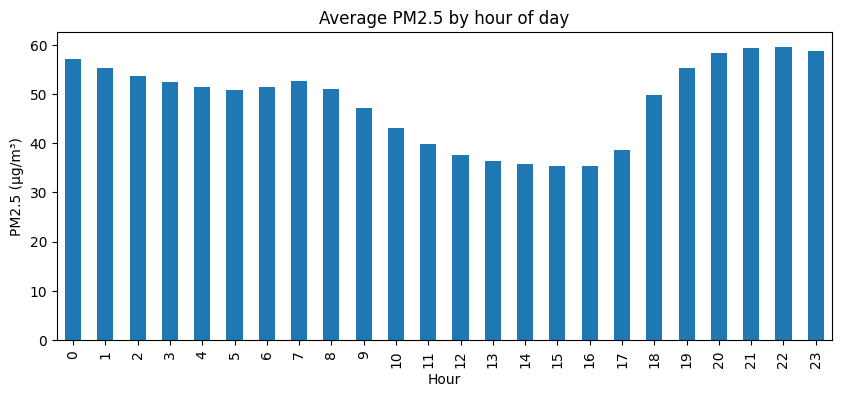

In [5]:
# 5. Average PM2.5 by hour of day
hourly_avg = df.groupby(df.index.hour)["pm2_5"].mean()
hourly_avg.plot(kind="bar", figsize=(10, 4), title="Average PM2.5 by hour of day")
plt.xlabel("Hour")
plt.ylabel("PM2.5 (µg/m³)")
plt.show()

# Check the time window 

In [6]:
def window(h):
    if 5 <= h < 8:   return "Morning"
    if 8 <= h < 11:  return "Office peak"
    if 16 <= h < 20: return "Afternoon peak"
    if h >= 21 or h < 5: return "Night"
    return "Other"

df["window"] = df.index.hour.map(window)
print(df.groupby("window")["pm2_5"].agg(["mean", "std"]))

                     mean        std
window                              
Afternoon peak  44.722441  26.427972
Morning         51.577980  39.645990
Night           55.922551  38.513160
Office peak     47.118676  36.303716
Other           40.533367  25.523938


In [7]:
# Monthly resample
print(df["pm2_5"].resample("MS").mean().round(1))

time
2022-10-01     40.4
2022-11-01     58.6
2022-12-01     73.3
2023-01-01     99.3
2023-02-01     69.8
2023-03-01     61.4
2023-04-01     55.8
2023-05-01     44.5
2023-06-01     31.7
2023-07-01     14.0
2023-08-01     32.4
2023-09-01     25.5
2023-10-01     45.4
2023-11-01     47.2
2023-12-01     48.2
2024-01-01     69.4
2024-02-01     65.7
2024-03-01     55.3
2024-04-01     45.6
2024-05-01     37.6
2024-06-01     29.4
2024-07-01     15.0
2024-08-01     15.4
2024-09-01     25.9
2024-10-01     47.8
2024-11-01     69.3
2024-12-01     83.0
2025-01-01    103.2
2025-02-01     95.9
2025-03-01     60.1
2025-04-01     40.7
2025-05-01     35.9
2025-06-01     28.5
2025-07-01     21.3
2025-08-01     20.7
2025-09-01     27.9
2025-10-01     47.2
2025-11-01     59.0
2025-12-01     68.2
2026-01-01     90.3
2026-02-01     78.1
2026-03-01     63.4
2026-04-01     38.8
2026-05-01     38.3
2026-06-01     35.3
2026-07-01     17.8
2026-08-01     15.8
2026-09-01     29.2
2026-10-01     68.3
Freq: MS, Name:

## Four years is better than two. The seasonal shape holds: January is the peak every year (99, 69, 103, 90), and July and August are the lowest (14 to 32).

- **Winters differ a lot.** The 2023-24 winter was much milder than the others (December 48, January 69), while January 2025 reached 103. A model can't predict a year's winter severity from the calendar, so the model will need to rely on recent PM2.5 levels, as I mentioned before.
  
- **October 2026 (73.7) is still only a few days.** Compare it to full-month figures only after more of the month has passed.

- **The data now has three winters before the most recent one.** You can hold out Dec 2025 to Feb 2026 as a test season and train on everything before it, which is a much harder test than a quiet week in September.


# Visualize the Data

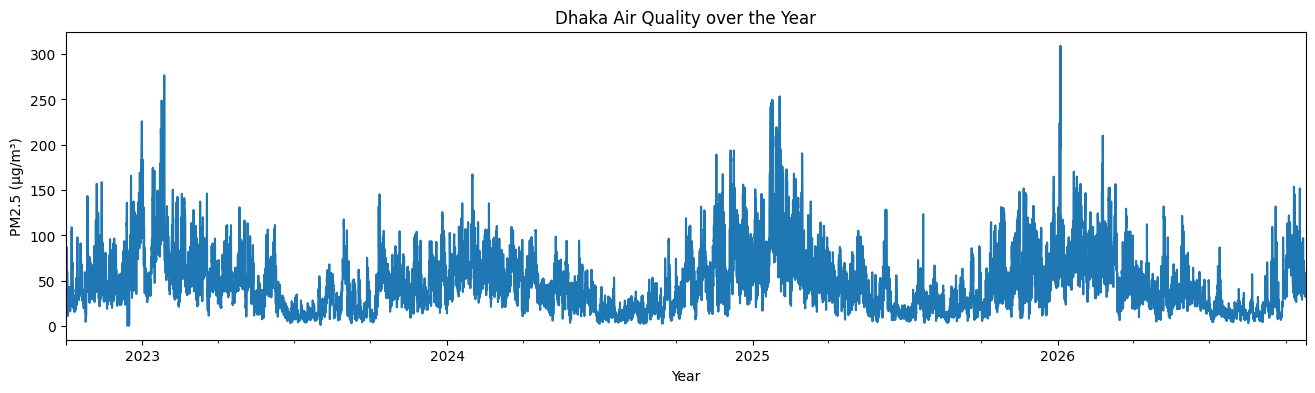

In [8]:
# Year-wise
df['pm2_5'].plot(figsize=(16,4), title="Dhaka Air Quality over the Year")
plt.ylabel("PM2.5 (µg/m³)")
plt.xlabel("Year")
plt.show()

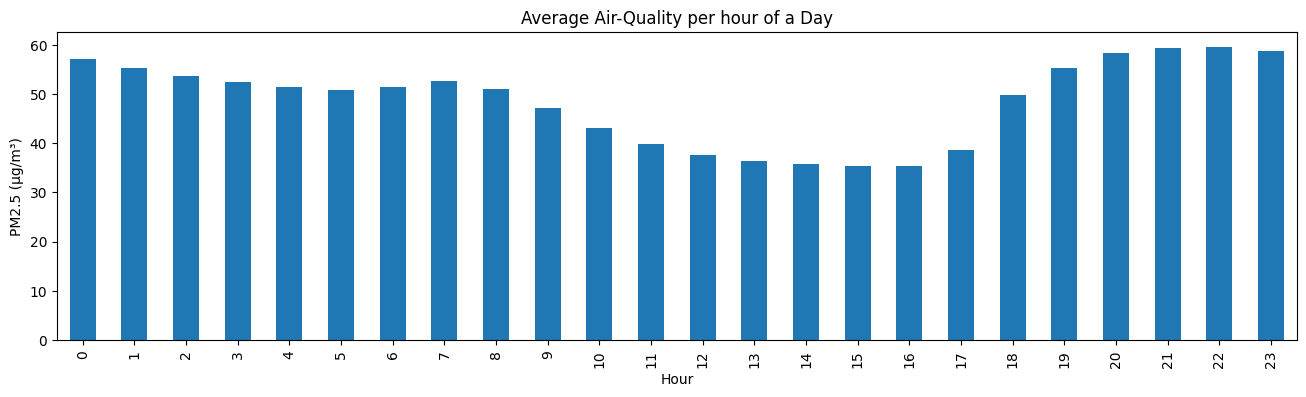

In [9]:
# An average day
hourly_avg= df.groupby(df.index.hour)["pm2_5"].mean()
hourly_avg.plot(figsize=(16,4), kind= "bar", title= "Average Air-Quality per hour of a Day")
plt.xlabel("Hour")
plt.ylabel("PM2.5 (µg/m³)")
plt.show()

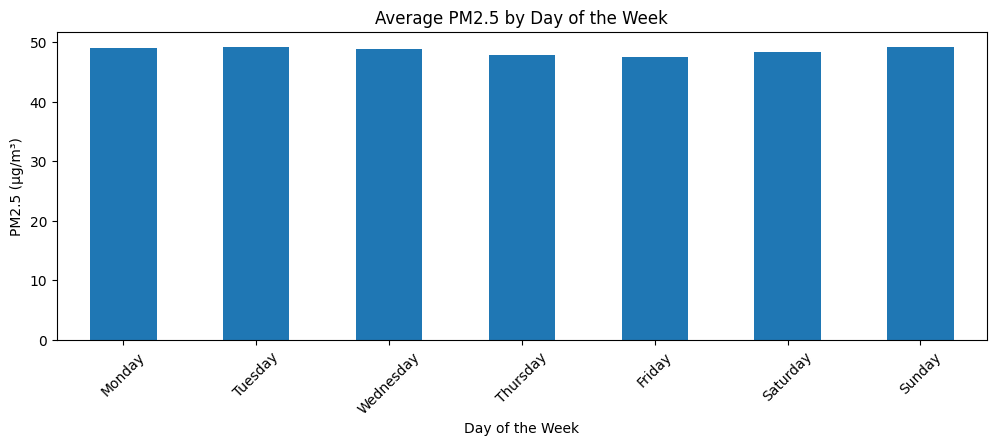

In [10]:
# Average PM2.5 for each day of the week
weekly_avg = df.groupby(df.index.day_name())["pm2_5"].mean()

# Put days in correct order
days_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekly_avg = weekly_avg.reindex(days_order)

# Plot
weekly_avg.plot(
    figsize=(12, 4),
    kind="bar",
    title="Average PM2.5 by Day of the Week"
)

plt.xlabel("Day of the Week")
plt.ylabel("PM2.5 (µg/m³)")
plt.xticks(rotation=45)
plt.show()

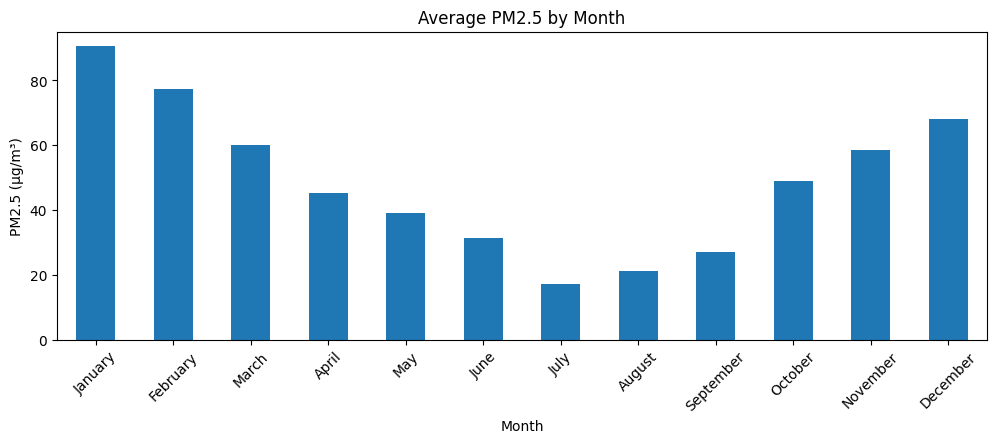

In [11]:
# Average PM2.5 for each month
monthly_avg = df.groupby(df.index.month_name())["pm2_5"].mean()

# Put months in correct chronological order
months_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

monthly_avg = monthly_avg.reindex(months_order)

# Plot
monthly_avg.plot(
    figsize=(12, 4),
    kind="bar",
    title="Average PM2.5 by Month"
)

plt.xlabel("Month")
plt.ylabel("PM2.5 (µg/m³)")
plt.xticks(rotation=45)
plt.show()

### Monthly PM2.5 Pattern

- The monthly average PM2.5 shows a clear seasonal pattern. **January has the highest average PM2.5 concentration (around 90 µg/m³)**, followed by February and December. PM2.5 gradually decreases from March through June and reaches its **lowest level in July (around 17 µg/m³)**. Concentrations then increase gradually from August through December.

- Overall, the results indicate that **PM2.5 concentrations are generally higher during the winter months (November–February) and lower during the monsoon/summer period (June–September)**. This strong seasonal pattern suggests that **month or season may be an important feature for the PM2.5 forecasting model**.

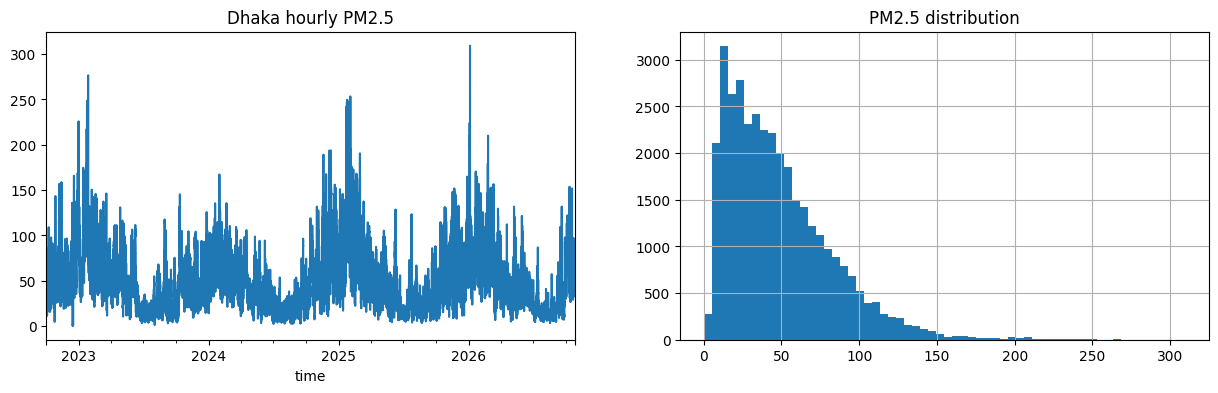

In [12]:
y = df["pm2_5"]

# 1. Full series and distribution
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
y.plot(ax=ax[0], title="Dhaka hourly PM2.5")
y.hist(bins=60, ax=ax[1])
ax[1].set_title("PM2.5 distribution")
plt.show()

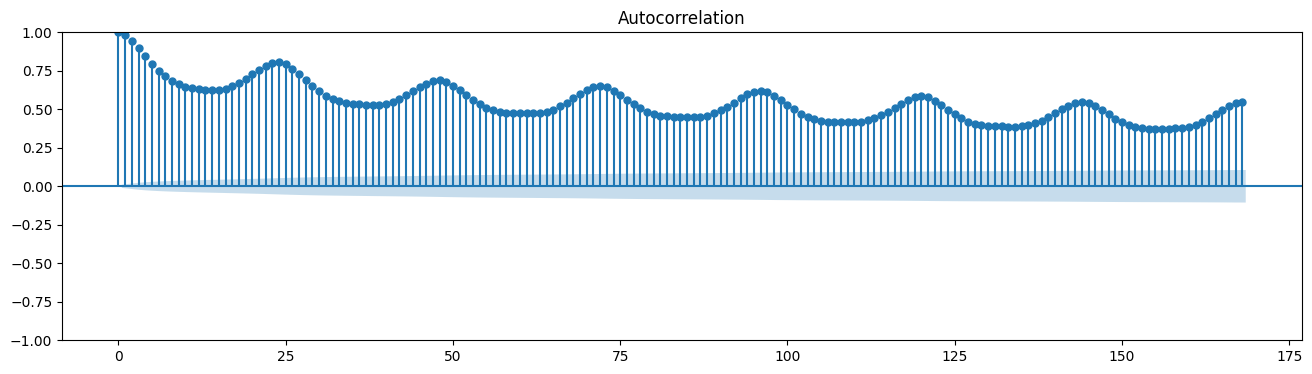

In [13]:
from statsmodels.graphics.tsaplots import plot_acf
fig, ax = plt.subplots(figsize=(16, 4))
plot_acf(y, lags=168, ax=ax)
plt.show()

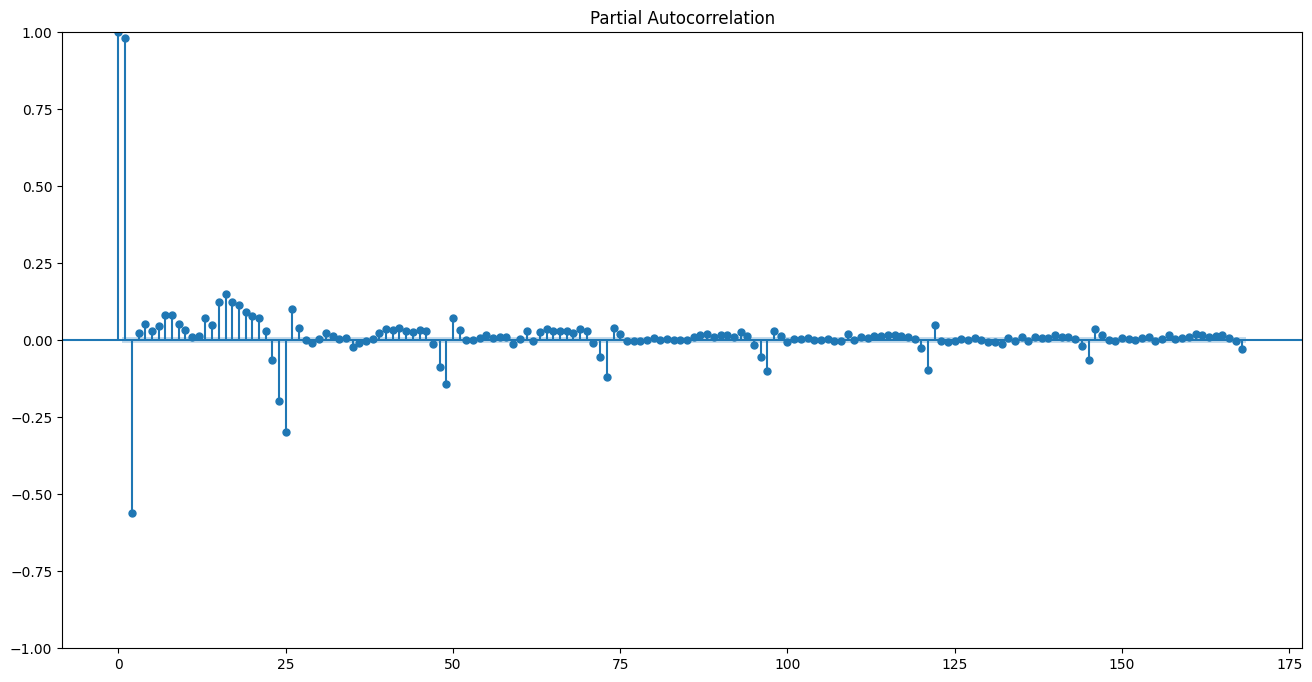

In [14]:
from statsmodels.graphics.tsaplots import plot_pacf
fig, ax = plt.subplots(figsize=(16, 8))
plot_pacf(y, lags=168, ax=ax)
plt.show()

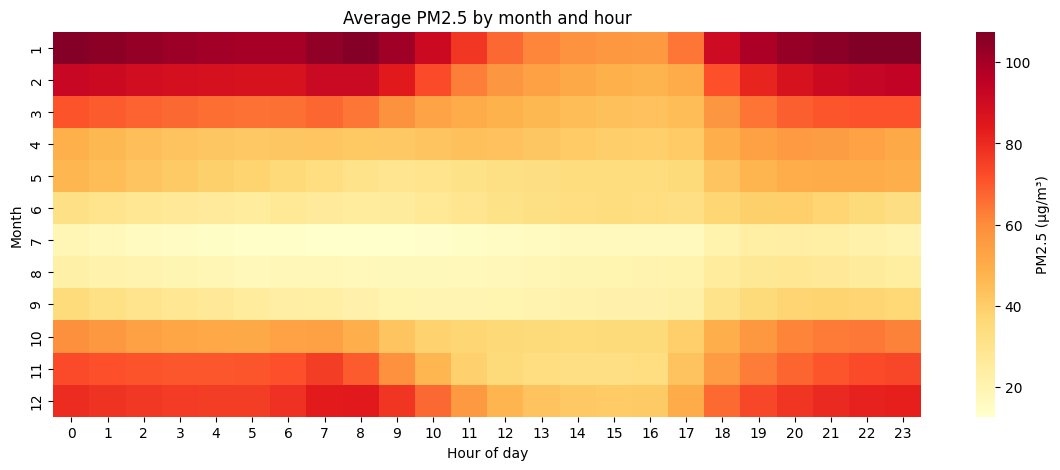

In [15]:
# 3. Hour-of-day by month heatmap
heat = y.groupby([y.index.month, y.index.hour]).mean().unstack()
plt.figure(figsize=(14, 5))
sns.heatmap(heat, cmap="YlOrRd", cbar_kws={"label": "PM2.5 (µg/m³)"})
plt.xlabel("Hour of day")
plt.ylabel("Month")
plt.title("Average PM2.5 by month and hour")
plt.show()

# The Baseline Model

                 season          model   MAE  RMSE  MAE / mean PM2.5
      Winter (Jan 2026)          naive 12.98 16.94             0.175
      Winter (Jan 2026) seasonal_naive 10.91 13.32             0.147
      Spring (Apr 2026)          naive 15.34 22.05             0.337
      Spring (Apr 2026) seasonal_naive 10.67 14.91             0.234
     Monsoon (Jul 2026)          naive 15.66 23.12             0.689
     Monsoon (Jul 2026) seasonal_naive 10.23 15.19             0.450
Post-monsoon (Sep 2026)          naive 39.52 48.98             0.928
Post-monsoon (Sep 2026) seasonal_naive 19.08 27.51             0.448


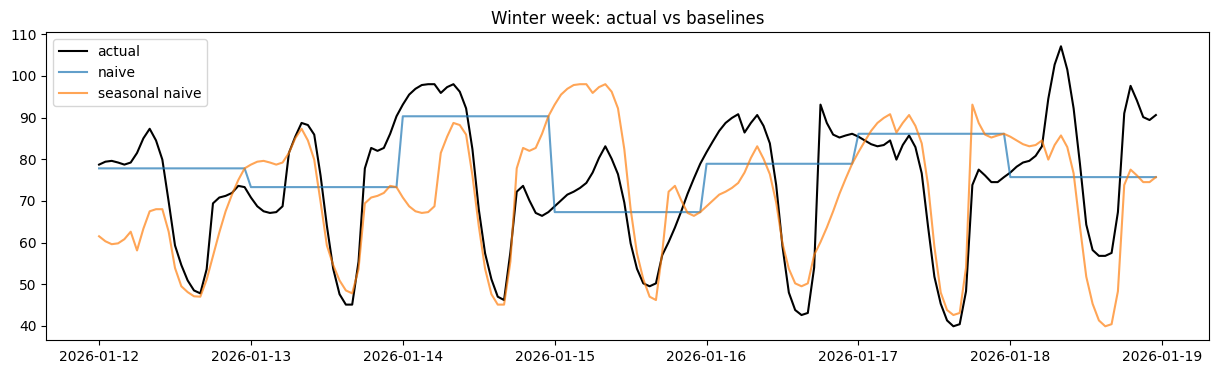

In [16]:
H = 24  # forecast horizon in hours

def naive(y, origin):
    """Repeat the last observed value for the next 24 hours."""
    last = y.loc[:origin - pd.Timedelta(hours=1)].iloc[-1]
    return np.repeat(last, H)

def seasonal_naive(y, origin):
    """Use the previous 24 hours as the forecast for the next 24 hours."""
    return y.loc[origin - pd.Timedelta(hours=24): origin - pd.Timedelta(hours=1)].values

def evaluate(y, origins, fn):
    actual, pred = [], []
    for o in origins:
        actual.append(y.loc[o: o + pd.Timedelta(hours=H - 1)].values)
        pred.append(fn(y, o))
    actual, pred = np.concatenate(actual), np.concatenate(pred)
    mae = mean_absolute_error(actual, pred)
    rmse = np.sqrt(mean_squared_error(actual, pred))
    return mae, rmse, mae / actual.mean()

# One test week per season; origins are midnight of each of the 7 days
test_weeks = {
    "Winter (Jan 2026)":      "2026-01-12",
    "Spring (Apr 2026)":      "2026-04-13",
    "Monsoon (Jul 2026)":     "2026-07-13",
    "Post-monsoon (Sep 2026)": "2026-09-14",
}

rows = []
for season, start in test_weeks.items():
    origins = pd.date_range(start, periods=7, freq="D")
    for name, fn in [("naive", naive), ("seasonal_naive", seasonal_naive)]:
        mae, rmse, rel = evaluate(y, origins, fn)
        rows.append({"season": season, "model": name,
                     "MAE": round(mae, 2), "RMSE": round(rmse, 2),
                     "MAE / mean PM2.5": round(rel, 3)})

results = pd.DataFrame(rows)
print(results.to_string(index=False))

# Plot one fold: actual vs both baselines
start = pd.Timestamp(test_weeks["Winter (Jan 2026)"])
origins = pd.date_range(start, periods=7, freq="D")
idx = pd.date_range(start, periods=7 * H, freq="h")
plt.figure(figsize=(15, 4))
plt.plot(idx, y.loc[idx], label="actual", color="black")
plt.plot(idx, np.concatenate([naive(y, o) for o in origins]), label="naive", alpha=0.7)
plt.plot(idx, np.concatenate([seasonal_naive(y, o) for o in origins]), label="seasonal naive", alpha=0.7)
plt.legend()
plt.title("Winter week: actual vs baselines")
plt.show()

Seasonal naive beats naive in all four weeks, so it’s the baseline your real model has to beat.

| Season | Seasonal naive MAE | Relative error |
|---|---:|---:|
| Winter (Jan) | 10.9 | 15% |
| Spring (Apr) | 10.7 | 23% |
| Monsoon (Jul) | 10.2 | 45% |
| Post-monsoon (Sep) | 19.1 | 45% |

## What the table shows

- **Absolute error is almost the same in three seasons (about 10 to 11 µg/m³), so relative error is what differs.** Winter looks best (15%) mostly because the level is high (the mean is about 74), and monsoon looks worst (45%) because the level is low (about 23). I predicted earlier that winter MAE would be much higher in absolute terms, and your data shows that was wrong for this week. Winter’s pattern is stable and repeats from day to day.

- **Sep 2026 is the hard week.** Seasonal naive’s MAE is almost double the others (19.1), and plain naive is at 39.5, with a mean of about 43 for the week. That week sits in the shift from monsoon air to winter air, when the level changes quickly and “same as yesterday” stops working. This is the kind of week where a model that uses weather-driven momentum and recent levels could do better. It’s also a week you’ll likely see in the live app every autumn.

- **Each fold is only one week (7 forecast origins).** Treat the exact numbers as rough. Before you compare models seriously, use several weeks per season, for example 3 to 4 start dates each.

# Try LightGBM

In [17]:
from lightgbm import LGBMRegressor

y = df["pm2_5"].asfreq("h")

# 1. Features, computed at t = the last hour known at forecast time
LAGS = [1, 2, 3, 6, 12, 24, 48]

def make_features(y):
    X = pd.DataFrame(index=y.index)
    X["y_t"] = y
    for k in LAGS:
        X[f"lag_{k}"] = y.shift(k)
    X["roll_24"] = y.rolling(24).mean()
    X["roll_72"] = y.rolling(72).mean()
    X["hour"] = y.index.hour
    X["month"] = y.index.month
    return X

X = make_features(y)

# 2. One model per horizon h = 1..24, trained only on data that ends before the test week
def lgbm_forecast_week(y, X, week_start, use_log=False):
    origins = pd.date_range(week_start, periods=7, freq="D")
    first_origin = origins[0]
    preds = np.zeros((len(origins), H))
    t_pred = origins - pd.Timedelta(hours=1)          # last known hour for each origin

    for h in range(1, H + 1):
        target = y.shift(-h)                           # value at t + h
        # leakage guard: the target time (t + h) must be before the first origin
        cutoff = first_origin - pd.Timedelta(hours=h + 1)
        train = pd.concat([X, target.rename("target")], axis=1).loc[:cutoff].dropna()
        y_train = np.log1p(train["target"]) if use_log else train["target"]

        model = LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=31,
                              min_child_samples=50, subsample=0.8, subsample_freq=1,
                              colsample_bytree=0.8, random_state=42, verbose=-1)
        model.fit(train.drop(columns="target"), y_train)

        p = model.predict(X.loc[t_pred])
        preds[:, h - 1] = np.expm1(p) if use_log else p

    return origins, preds

def score(y, origins, preds):
    actual = np.concatenate([y.loc[o: o + pd.Timedelta(hours=H - 1)].values for o in origins])
    pred = preds.ravel()
    mae = mean_absolute_error(actual, pred)
    rmse = np.sqrt(mean_squared_error(actual, pred))
    return mae, rmse, mae / actual.mean()

# 3. Run all four test weeks, with and without the log transform
rows = []
for use_log, name in [(False, "lgbm"), (True, "lgbm_log")]:
    for season, start in test_weeks.items():
        origins, preds = lgbm_forecast_week(y, X, start, use_log=use_log)
        mae, rmse, rel = score(y, origins, preds)
        rows.append({"season": season, "model": name,
                     "MAE": round(mae, 2), "RMSE": round(rmse, 2),
                     "MAE / mean PM2.5": round(rel, 3)})

lgbm_results = pd.DataFrame(rows)

# 4. Side-by-side with the baselines
all_results = pd.concat([results, lgbm_results]).sort_values(["season", "MAE"])
print(all_results.to_string(index=False))

                 season          model   MAE  RMSE  MAE / mean PM2.5
     Monsoon (Jul 2026)       lgbm_log  5.73  9.43             0.252
     Monsoon (Jul 2026)           lgbm  6.52 10.08             0.287
     Monsoon (Jul 2026) seasonal_naive 10.23 15.19             0.450
     Monsoon (Jul 2026)          naive 15.66 23.12             0.689
Post-monsoon (Sep 2026)           lgbm 12.34 19.00             0.290
Post-monsoon (Sep 2026)       lgbm_log 12.53 19.08             0.294
Post-monsoon (Sep 2026) seasonal_naive 19.08 27.51             0.448
Post-monsoon (Sep 2026)          naive 39.52 48.98             0.928
      Spring (Apr 2026)           lgbm  8.49 11.76             0.187
      Spring (Apr 2026)       lgbm_log  8.97 12.13             0.197
      Spring (Apr 2026) seasonal_naive 10.67 14.91             0.234
      Spring (Apr 2026)          naive 15.34 22.05             0.337
      Winter (Jan 2026)       lgbm_log  8.54 11.17             0.115
      Winter (Jan 2026)           

LightGBM beats seasonal naive in all four weeks, and both LightGBM variants beat both baselines everywhere.

| Season | Seasonal naive | LightGBM | LightGBM (log) | Best vs baseline |
|---|---:|---:|---:|---:|
| Winter | 10.91 | 9.09 | **8.54** | -22% |
| Spring | 10.67 | **8.49** | 8.97 | -20% |
| Monsoon | 10.23 | 6.52 | **5.73** | -44% |
| Post-monsoon | 19.08 | **12.34** | 12.53 | -35% |

- **The biggest gains are where the baseline was weakest.** In the September transition week, the error drops from 19.1 to 12.3, and in the monsoon from 10.2 to 5.7. That fits the idea that recent-level features help most when the day-to-day pattern shifts.

- **The log transform is not a clear win.** It helps in winter and monsoon, and slightly hurts in spring and post-monsoon. With one week per season, differences of 0.2 to 0.9 µg/m³ are within noise, so don’t commit to it yet.

- **Winter’s gain is the smallest (22%).** That is the season your app matters most for, so it’s worth looking at more closely.

**Be careful with these numbers.** Each season is one week (7 forecast origins), so a model can look good or bad by luck. This also uses 24 separate models, each given the same features.

## Next steps

1. **Add more test weeks.** Use 3 to 4 start dates per season, such as Jan 5, 12, 19, and 26, and average the results. This is the most important step before you trust any comparison. It also settles the log-transform question.

2. **Check error by forecast hour.** Compute MAE separately for h = 1 to 24 and plot it for LightGBM against seasonal naive. I expect LightGBM to win early and the gap to narrow at long horizons.

3. **Look at the winter week plot.** Plot actual against LightGBM for the January week. If it misses spikes, that tells you which features to add.

done: Winter (Jan 2026)
done: Spring (Apr 2026)
done: Monsoon (Jul 2026)
done: Post-monsoon (Sep 2026)
                                         mean    min    max
season                  model                              
Monsoon (Jul 2026)      lgbm_log         4.41   2.85   5.89
                        lgbm             4.61   2.66   6.52
                        seasonal_naive   6.46   3.42  10.23
                        naive            8.39   4.40  15.66
Post-monsoon (Sep 2026) lgbm            10.15   6.30  14.07
                        lgbm_log        10.62   5.94  16.02
                        seasonal_naive  15.06   9.91  20.83
                        naive           18.97   8.77  39.52
Spring (Apr 2026)       lgbm             7.77   6.22   9.87
                        lgbm_log         7.86   5.85  10.15
                        seasonal_naive  10.42   8.50  13.70
                        naive           12.34   9.21  15.34
Winter (Jan 2026)       lgbm_log        11.34   8.54  15.

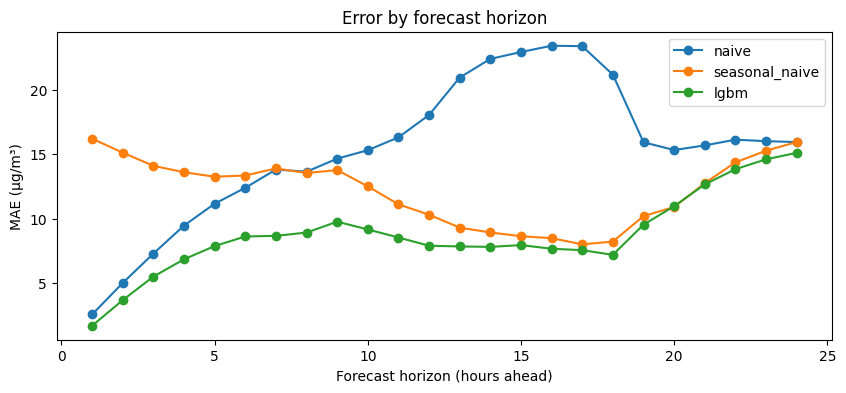

In [18]:
weeks = {
    "Winter (Jan 2026)":       ["2026-01-05", "2026-01-12", "2026-01-19", "2026-01-26"],
    "Spring (Apr 2026)":       ["2026-04-06", "2026-04-13", "2026-04-20", "2026-04-27"],
    "Monsoon (Jul 2026)":      ["2026-07-06", "2026-07-13", "2026-07-20", "2026-07-27"],
    "Post-monsoon (Sep 2026)": ["2026-09-07", "2026-09-14", "2026-09-21", "2026-09-28"],
}

records = []
abs_err = {}   # model -> list of (7, H) absolute-error arrays, for the by-horizon plot

for season, starts in weeks.items():
    for start in starts:
        origins = pd.date_range(start, periods=7, freq="D")
        actual = np.stack([y.loc[o: o + pd.Timedelta(hours=H - 1)].values for o in origins])

        preds = {
            "naive": np.stack([naive(y, o) for o in origins]),
            "seasonal_naive": np.stack([seasonal_naive(y, o) for o in origins]),
        }
        for use_log, name in [(False, "lgbm"), (True, "lgbm_log")]:
            _, p = lgbm_forecast_week(y, X, start, use_log=use_log)
            preds[name] = p

        for name, p in preds.items():
            err = np.abs(actual - p)
            records.append({
                "season": season, "week": start, "model": name,
                "MAE": err.mean(),
                "RMSE": np.sqrt(((actual - p) ** 2).mean()),
                "rel": err.mean() / actual.mean(),
            })
            abs_err.setdefault(name, []).append(err)
    print("done:", season)

weekly = pd.DataFrame(records)

# Mean / min / max MAE across the 4 weeks of each season
summary = (weekly.groupby(["season", "model"])["MAE"]
           .agg(["mean", "min", "max"]).round(2)
           .sort_values(["season", "mean"]))
print(summary.to_string())

# One-line view: mean MAE per season, models side by side, plus the overall average
pivot = weekly.pivot_table(index="season", columns="model", values="MAE", aggfunc="mean").round(2)
pivot.loc["ALL SEASONS"] = pivot.mean().round(2)
print(pivot[["naive", "seasonal_naive", "lgbm", "lgbm_log"]].to_string())

# Weeks where each LightGBM variant beat seasonal naive (out of 16)
wide = weekly.pivot_table(index=["season", "week"], columns="model", values="MAE")
for m in ["lgbm", "lgbm_log"]:
    print(f"{m} beat seasonal_naive in {(wide[m] < wide['seasonal_naive']).sum()} of {len(wide)} weeks")

# MAE by forecast hour (h = 1..24), all 16 weeks pooled
plt.figure(figsize=(10, 4))
for name in ["naive", "seasonal_naive", "lgbm"]:
    by_h = np.concatenate(abs_err[name], axis=0).mean(axis=0)
    plt.plot(range(1, H + 1), by_h, marker="o", label=name)
plt.xlabel("Forecast horizon (hours ahead)")
plt.ylabel("MAE (µg/m³)")
plt.title("Error by forecast horizon")
plt.legend()
plt.show()

LightGBM beat seasonal naive in all 16 weeks, with both variants. That is a much stronger result than the four-week table, so the model is clearly working.

| Season | Seasonal naive | LightGBM | LightGBM (log) | Best vs baseline |
|---|---:|---:|---:|---:|
| Winter | 16.68 | 12.43 | **11.34** | -32% |
| Spring | 10.42 | **7.77** | 7.86 | -25% |
| Monsoon | 6.46 | 4.61 | **4.41** | -32% |
| Post-monsoon | 15.06 | **10.15** | 10.62 | -33% |
| **All** | **12.16** | **8.74** | **8.56** | **-30%** |

## What changed from the earlier single-week reading

- **I was wrong about winter being easy.** I said absolute error was nearly the same across seasons, based on one January week. Averaged over four weeks, winter has the highest baseline error (16.7), and one week reached 21.4. Winter and post-monsoon are the hard seasons.

- **The gain is fairly even, 25% to 33% in every season.** It’s not concentrated in one week or one season.

## Log transform: roughly a tie
- It helps in winter (11.34 vs 12.43, and lower at both the best and worst week) and in monsoon.
- It’s slightly worse in post-monsoon and spring.
- The overall difference is 8.56 vs 8.74, about 2%.
- Winter is the season where it helps most and where your app matters most, so I’d lean toward the log version. But choose plain lgbm if you’d rather  have the simpler pipeline, because the case is weak.

### What it shows (values read off the plot, so approximate)

- **LightGBM is best at every horizon.** At h = 1 its error is about 1.7, against 2.6 for naive and 16 for seasonal naive.

- **Naive wins only briefly.** It beats seasonal naive for the first 6 to 7 hours, then it collapses to about 23 around h = 16 to 17.

- **LightGBM’s advantage disappears late in the day.** From about h = 19 to 24 its error is within 0 to 1 µg/m³ of seasonal naive, and the two lines nearly touch at h = 20 to 21. There, the model is mostly repeating yesterday.

- **LightGBM’s error peaks at about 9.7 around h = 9, falls to about 7 near h = 18, then climbs to about 15 at h = 24.**

## What I got wrong

I expected seasonal naive to be flat and LightGBM to rise steadily. Neither happened, and the reason matters. Every origin in this test is midnight, so horizon and hour of day are the same thing. In your code h = 1 is the 00:00 hour and h = 24 is the 23:00 hour. The U-shape is therefore mostly a time-of-day effect: yesterday’s value is a poor guide for the small hours (seasonal naive is worst at about 16 for h = 1) and a better one for the late afternoon (best at about 8 around h = 17 to 18). I can’t separate “far ahead” from “this time of day” with midnight origins only.

## What this means for your four maps (h = hour + 1)

- **Morning (5-8) and Office peak (8-11):** h = 6 to 11. LightGBM is about 9 against about 13 for seasonal naive, a clear win.

- **Afternoon peak (16-20):** h = 17 to 20. It is nearly a tie, roughly 9 against 9.4.

- **Night (21-5):** the hours 22 to 24 are at h = 22 to 24, where LightGBM gains only about 0.5 to 0.8. The hours 0 to 4 look great (about 5 against 14), but only because they’re 1 to 5 hours after the last known observation at 23:00.

That last point leads to the real issue. Your app will forecast from the current hour, not from midnight, so the lead time to each window changes with when someone opens it. Opening at 4 pm, the night window is 5 to 13 hours ahead, not 1 to 5.

## Next step

1. **Evaluate from more origin hours.** Use origins at 00:00, 06:00, 12:00 and 18:00 on the same 16 weeks (28 origins per week instead of 7). In `lgbm_forecast_week`, the training cutoff rule `first_origin - (h + 1) hours` still works, but the origin dates and `t_pred` need to include the hour.

2. **Score window-level error at the lead time the app will use.** For each origin, find the next occurrence of each window and average the forecast and actual over its hours. Compare MAE against seasonal naive, per window.

3. **Check the ranking.** On days when the actual Night average exceeds the Afternoon peak average, does the forecast agree?

If you want, I can write the multi-origin loop and the window scoring. Tell me which origin hours you expect the app to refresh at (hourly, as you planned, or a few times a day), because that decides the origin set.

### This version uses origins at 00:00, 06:00, 12:00 and 18:00 on each of the 16 weeks (28 per week). It scores your four windows at the lead time the app will actually have, and it checks whether the forecast ranks the windows correctly. It reuses y, X, H, weeks, naive, seasonal_naive and window from your notebook.

In [19]:
ORIGIN_HOURS = [0, 6, 12, 18]
WINDOWS = ["Morning", "Office peak", "Afternoon peak", "Night"]
MODELS = ["naive", "seasonal_naive", "lgbm", "lgbm_log"]
hour_to_win = np.array([window(h) for h in range(24)])   # uses your window() function

def lgbm_multi(y, X, week_start, origins, use_log=False):
    """Train once on data that ends before the week starts; forecast 24h from every origin."""
    first_origin = pd.Timestamp(week_start)
    t_pred = origins - pd.Timedelta(hours=1)               # last known hour for each origin
    preds = np.zeros((len(origins), H))
    for h in range(1, H + 1):
        target = y.shift(-h)
        cutoff = first_origin - pd.Timedelta(hours=h + 1)  # target time must be before the week
        train = pd.concat([X, target.rename("target")], axis=1).loc[:cutoff].dropna()
        y_train = np.log1p(train["target"]) if use_log else train["target"]
        model = LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=31,
                              min_child_samples=50, subsample=0.8, subsample_freq=1,
                              colsample_bytree=0.8, random_state=42, verbose=-1)
        model.fit(train.drop(columns="target"), y_train)
        p = model.predict(X.loc[t_pred])
        preds[:, h - 1] = np.expm1(p) if use_log else p
    return preds

rows, actual_store, origin_store = [], [], []
pred_store = {m: [] for m in MODELS}

for season, starts in weeks.items():
    for start in starts:
        days = pd.date_range(start, periods=7, freq="D")
        origins = pd.DatetimeIndex([d + pd.Timedelta(hours=hh) for d in days for hh in ORIGIN_HOURS])

        actual = np.stack([y.loc[o: o + pd.Timedelta(hours=H - 1)].values for o in origins])
        preds = {
            "naive": np.stack([naive(y, o) for o in origins]),
            "seasonal_naive": np.stack([seasonal_naive(y, o) for o in origins]),
            "lgbm": lgbm_multi(y, X, start, origins, use_log=False),
            "lgbm_log": lgbm_multi(y, X, start, origins, use_log=True),
        }

        # Which window does each of the 24 forecast hours belong to? (hour of day of origin + k)
        hod = (origins.hour.values[:, None] + np.arange(H)) % 24
        win_grid = hour_to_win[hod]

        def win_mean(arr):
            """Average over the window's hours that fall inside the next 24 hours -> (n_origins, 4)."""
            return np.stack([(arr * (win_grid == w)).sum(1) / (win_grid == w).sum(1)
                             for w in WINDOWS], axis=1)

        a_w = win_mean(actual)
        actual_store.append(a_w)
        origin_store.append(origins.hour.values)
        for name, p in preds.items():
            p_w = win_mean(p)
            pred_store[name].append(p_w)
            err = np.abs(a_w - p_w)
            for j, w in enumerate(WINDOWS):
                rows.append(pd.DataFrame({"season": season, "week": start,
                                          "origin_hour": origins.hour.values,
                                          "model": name, "window": w, "abs_err": err[:, j]}))
    print("done:", season)

long = pd.concat(rows, ignore_index=True)

# 1. Window-level MAE, all origins pooled
tab = (long.pivot_table(index="window", columns="model", values="abs_err", aggfunc="mean")
       .loc[WINDOWS, MODELS].round(2))
tab.loc["ALL WINDOWS"] = tab.mean().round(2)
tab["lgbm vs seasonal_naive %"] = ((1 - tab["lgbm"] / tab["seasonal_naive"]) * 100).round(0)
print(tab.to_string(), "\n")

# 2. Same, split by origin hour (= how far ahead the window is when the user opens the app)
sub = long[long.model.isin(["seasonal_naive", "lgbm"])]
by_origin = (sub.pivot_table(index=["window", "origin_hour"], columns="model",
                             values="abs_err", aggfunc="mean").round(2))
by_origin["gain %"] = ((1 - by_origin["lgbm"] / by_origin["seasonal_naive"]) * 100).round(0)
print(by_origin.to_string(), "\n")

# 3. By season (mean over the 4 windows)
by_season = (long.pivot_table(index="season", columns="model", values="abs_err", aggfunc="mean")
             [MODELS].round(2))
print(by_season.to_string(), "\n")

# 4. Does the forecast rank the windows correctly? (agreement on which window is higher)
A = np.vstack(actual_store)
pairs = [(i, j) for i in range(4) for j in range(i + 1, 4)]
rank = pd.DataFrame(index=[f"{WINDOWS[i]} vs {WINDOWS[j]}" for i, j in pairs])
rank["mean |actual diff|"] = [np.abs(A[:, i] - A[:, j]).mean().round(1) for i, j in pairs]
for name in ["seasonal_naive", "lgbm", "lgbm_log"]:
    P = np.vstack(pred_store[name])
    rank[name] = [(((A[:, i] - A[:, j]) * (P[:, i] - P[:, j])) > 0).mean().round(2) for i, j in pairs]
print(rank.to_string())

done: Winter (Jan 2026)
done: Spring (Apr 2026)
done: Monsoon (Jul 2026)
done: Post-monsoon (Sep 2026)
model           naive  seasonal_naive   lgbm  lgbm_log  lgbm vs seasonal_naive %
window                                                                          
Morning         12.72           11.79   9.64      9.21                      18.0
Office peak     12.98           11.65   9.02      8.91                      23.0
Afternoon peak  11.69            7.77   6.94      6.81                      11.0
Night           13.96           12.73  10.88     10.35                      15.0
ALL WINDOWS     12.84           10.98   9.12      8.82                      17.0 

model                        lgbm  seasonal_naive  gain %
window         origin_hour                               
Afternoon peak 0             8.00            8.03     0.0
               6             7.30            8.03     9.0
               12            6.31            8.03    21.0
               18            6.17     

##  The model’s advantage fades with lead time

Seasonal naive’s error depends only on which hours are being predicted, not on when you ask. So the clean comparison is the same target hours asked from different origins (lead is hours after the last observation):

| Window (same target hours) | Lead | Gain over seasonal naive |
|---|---:|---:|
| Afternoon peak | 5–8 h | 21% |
| Afternoon peak | 11–14 h | 9% |
| Afternoon peak | 17–20 h | 0% |
| Night | 4–11 h | 16% |
| Night | 10–17 h | 8% |
| Night | 16–23 h | 6% |
| Morning | 12–14 h | 2% |
| Morning | 18–20 h | -3% |
| Office peak | 15–17 h | 8% |
| Office peak | 21–23 h | 5% |

### When the window is within about 8 hours, the gain is 20% to 45% (Office peak from 6 am is 46%). Beyond about 12 hours the model is barely better than repeating yesterday. This matches the horizon plot.

### For the app, whichever window is more than half a day away will carry little skill beyond “same as yesterday”. You can’t fix that with tuning on this feature set. It’s an honest limit to show on the page.

## What I’d change in the design
- Merge Morning and Office peak into one “Morning (5-11)” window, or keep both but don’t claim an order between them.
- Show a range next to every value, wider for windows further away.
- Reconsider four maps. Your series is one city-wide number, so four maps would show the same single Dhaka marker in four colors. Four cards (value, range, AQI category) plus a 24-hour curve carries the same information more clearly. A small Dhaka map as decoration is fine.

### This code reruns your 16 weeks to calibrate the ranges, then scores 6 held-out weeks (Dec 8, 15, 22, 29 of 2025 and Oct 5, 12 of 2026) without any tuning. It reuses lgbm_multi, naive, seasonal_naive, window, ORIGIN_HOURS, WINDOWS, hour_to_win, y, X, H and weeks from

In [20]:
def win_mean(arr, win_grid):
    """Average each window's hours inside the next 24h -> (n_origins, 4)."""
    return np.stack([(arr * (win_grid == w)).sum(1) / (win_grid == w).sum(1)
                     for w in WINDOWS], axis=1)

def run_weeks(weeks_dict, model_names=("seasonal_naive", "lgbm_log")):
    out = []
    for season, starts in weeks_dict.items():
        for start in starts:
            days = pd.date_range(start, periods=7, freq="D")
            origins = pd.DatetimeIndex([d + pd.Timedelta(hours=hh)
                                        for d in days for hh in ORIGIN_HOURS])
            actual = np.stack([y.loc[o: o + pd.Timedelta(hours=H - 1)].values for o in origins])

            preds = {}
            if "seasonal_naive" in model_names:
                preds["seasonal_naive"] = np.stack([seasonal_naive(y, o) for o in origins])
            if "lgbm_log" in model_names:
                preds["lgbm_log"] = lgbm_multi(y, X, start, origins, use_log=True)

            hod = (origins.hour.values[:, None] + np.arange(H)) % 24
            win_grid = hour_to_win[hod]
            a_w = win_mean(actual, win_grid)

            for name, p in preds.items():
                p_w = win_mean(p, win_grid)
                for j, w in enumerate(WINDOWS):
                    out.append(pd.DataFrame({
                        "season": season, "week": start, "origin_hour": origins.hour.values,
                        "model": name, "window": w,
                        "actual": a_w[:, j], "pred": p_w[:, j]}))
        print("done:", season)
    d = pd.concat(out, ignore_index=True)
    d["err"] = d["actual"] - d["pred"]       # signed: positive = model under-predicted
    d["abs_err"] = d["err"].abs()
    return d

holdout_weeks = {
    "Winter (Dec 2025)": ["2025-12-08", "2025-12-15", "2025-12-22", "2025-12-29"],
    "Autumn (Oct 2026)": ["2026-10-05", "2026-10-12"],
}

calib = run_weeks(weeks)            # your 16 weeks, used only to set the ranges
hold = run_weeks(holdout_weeks)     # untouched weeks, used only to judge

# 1. Held-out accuracy: window-level MAE
t = hold.pivot_table(index="window", columns="model", values="abs_err", aggfunc="mean").round(2)
t = t.loc[WINDOWS, ["seasonal_naive", "lgbm_log"]]
t.loc["ALL WINDOWS"] = t.mean().round(2)
t["gain %"] = ((1 - t["lgbm_log"] / t["seasonal_naive"]) * 100).round(0)
print(t.to_string(), "\n")

by_season = hold.pivot_table(index="season", columns="model", values="abs_err",
                             aggfunc="mean").round(2)
by_season["gain %"] = ((1 - by_season["lgbm_log"] / by_season["seasonal_naive"]) * 100).round(0)
print(by_season.to_string(), "\n")

# 2. Bias: does the model systematically under- or over-predict on held-out weeks?
print(hold.groupby(["season", "model"])["err"].mean().round(2).to_string(), "\n")

# 3. 80% ranges: 10th/90th percentile of signed error, by window and lead (origin hour)
q = (calib[calib.model == "lgbm_log"]
     .groupby(["window", "origin_hour"])["err"].quantile([0.1, 0.9]).unstack()
     .rename(columns={0.1: "q10", 0.9: "q90"}).round(1))
print(q.to_string(), "\n")
q.reset_index().to_csv("pm25_intervals.csv", index=False)   # the app will load this

# 4. Do those ranges hold on the held-out weeks? Target is about 0.80
h = hold[hold.model == "lgbm_log"].merge(q.reset_index(), on=["window", "origin_hour"])
h["lo"] = h["pred"] + h["q10"]
h["hi"] = h["pred"] + h["q90"]
h["covered"] = (h["actual"] >= h["lo"]) & (h["actual"] <= h["hi"])
print("overall coverage:", round(h["covered"].mean(), 2))
print(h.groupby("window")["covered"].mean().round(2).to_string())
print(h.groupby("season")["covered"].mean().round(2).to_string())
print(h.groupby("origin_hour")["covered"].mean().round(2).to_string())
print("average range width by window:")
print((h["hi"] - h["lo"]).groupby(h["window"]).mean().round(1).to_string())

done: Winter (Jan 2026)
done: Spring (Apr 2026)
done: Monsoon (Jul 2026)
done: Post-monsoon (Sep 2026)
done: Winter (Dec 2025)
done: Autumn (Oct 2026)
model           seasonal_naive  lgbm_log  gain %
window                                          
Morning                  21.17     17.92    15.0
Office peak              19.70     18.04     8.0
Afternoon peak           10.58     10.92    -3.0
Night                    20.07     17.65    12.0
ALL WINDOWS              17.88     16.13    10.0 

model              lgbm_log  seasonal_naive  gain %
season                                             
Autumn (Oct 2026)     16.32           18.08    10.0
Winter (Dec 2025)     16.04           17.78    10.0 

season             model         
Autumn (Oct 2026)  lgbm_log          4.69
                   seasonal_naive   -1.92
Winter (Dec 2025)  lgbm_log          7.67
                   seasonal_naive    2.16 

                             q10   q90
window         origin_hour            
Afternoon pe

### The held-out result is weaker than the 16-week result, and it shows two problems to fix before building the pipeline: the log model under-predicts, and the ranges are too narrow.

## Accuracy: about half the earlier gain

### On the 6 untouched weeks, LightGBM (log) beats seasonal naive by 10% overall (16.13 vs 17.88), and by 10% in both December and October. The 16-week estimate was 20%, and that number was optimistic. I chose the log variant using those same weeks, and the held-out weeks are also a harder regime (higher levels, rising into winter), with errors 1.6 to 1.8 times larger in absolute terms. The honest summary is a real but modest gain.

### By window: Morning 15%, Night 12%, Office peak 8%, Afternoon peak -3% (10.92 vs 10.58). On new data, the model does not beat “same as yesterday” for the afternoon window. That fits the earlier results, where the afternoon gain was already the smallest.

## Bias: the log model runs low

### The mean signed error (actual minus forecast) for lgbm_log is +4.7 in October and +7.7 in December, so it under-predicts. Seasonal naive stays within ±2.2. In December, 7.7 of the 16.0 average error is a one-direction offset.

## Two clues about the cause:

### The calibration quantiles are skewed. The 90th percentile is further from zero than the 10th in 15 of 16 rows (Night from 06:00 is -15.2 vs +23.2), so the model under-predicts on the calibration weeks too, only less.
### A model trained on log values and converted back with expm1 predicts closer to the median than the mean, which runs low on a series with large pollution spikes. A rising season could add to it, because lag features trail a rising level.

- I can’t separate these causes from this output.

- Coverage: 0.60 instead of 0.80

- October is 0.50 and December 0.64. The worst cases are windows 12 or 18 hours ahead (0.53, 0.58). There are two reasons:

### The offsets were measured on weeks whose errors were about half this size, since they include monsoon and spring, and they are fixed amounts in µg/m³.They are centered on a forecast that’s biased low.

### Fix the bias first, because a range around a shifted forecast can’t cover well at any width.

In [21]:
# 1. Run plain lgbm (no log) on the held-out weeks; lgbm_log and seasonal_naive are already in `hold`
def run_lgbm_plain(weeks_dict):
    out = []
    for season, starts in weeks_dict.items():
        for start in starts:
            days = pd.date_range(start, periods=7, freq="D")
            origins = pd.DatetimeIndex([d + pd.Timedelta(hours=hh)
                                        for d in days for hh in ORIGIN_HOURS])
            actual = np.stack([y.loc[o: o + pd.Timedelta(hours=H - 1)].values for o in origins])
            hod = (origins.hour.values[:, None] + np.arange(H)) % 24
            win_grid = hour_to_win[hod]
            a_w = win_mean(actual, win_grid)
            p_w = win_mean(lgbm_multi(y, X, start, origins, use_log=False), win_grid)
            for j, w in enumerate(WINDOWS):
                out.append(pd.DataFrame({"season": season, "week": start,
                                         "origin_hour": origins.hour.values,
                                         "model": "lgbm", "window": w,
                                         "actual": a_w[:, j], "pred": p_w[:, j]}))
        print("done:", season)
    d = pd.concat(out, ignore_index=True)
    d["err"] = d["actual"] - d["pred"]
    d["abs_err"] = d["err"].abs()
    return d

hold_all = pd.concat([hold, run_lgbm_plain(holdout_weeks)], ignore_index=True)

# 2. One row per (week, forecast origin, window) with a column per model
grp = ["season", "week", "model", "window"]
hold_all["k"] = hold_all.groupby(grp).cumcount()       # position of the origin inside its week
key = ["season", "week", "k", "window"]
wide = hold_all.pivot(index=key, columns="model", values="pred")
ref = hold_all[hold_all.model == "seasonal_naive"].set_index(key)
actual = ref["actual"]

# 3. Blends (fixed equal weights: don't tune these on the held-out weeks)
wide["blend_sn_lgbm"] = (wide["seasonal_naive"] + wide["lgbm"]) / 2
wide["blend_sn_log"] = (wide["seasonal_naive"] + wide["lgbm_log"]) / 2
wide["blend_all3"] = wide[["seasonal_naive", "lgbm", "lgbm_log"]].mean(axis=1)
cands = ["seasonal_naive", "lgbm", "lgbm_log", "blend_sn_lgbm", "blend_sn_log", "blend_all3"]

err = pd.DataFrame({m: actual - wide[m] for m in cands})   # positive = under-predicted

# 4. Overall accuracy and bias
summary = pd.DataFrame({"MAE": err.abs().mean(), "bias": err.mean()}).round(2)
summary["gain % vs seasonal_naive"] = ((1 - summary["MAE"] / summary.loc["seasonal_naive", "MAE"]) * 100).round(0)
print(summary.to_string(), "\n")

# 5. MAE by window and by season
win_lvl = err.index.get_level_values("window")
sea_lvl = err.index.get_level_values("season")
print(err.abs().groupby(win_lvl).mean().loc[WINDOWS].round(2).to_string(), "\n")
print(err.abs().groupby(sea_lvl).mean().round(2).to_string(), "\n")

# 6. Is the bias systematic or just a few weeks? Mean signed error per week
wk = err[["seasonal_naive", "lgbm", "lgbm_log"]].groupby(
    [err.index.get_level_values("season"), err.index.get_level_values("week")]).mean().round(1)
print(wk.to_string(), "\n")

# 7. Bias by window
print(err[["seasonal_naive", "lgbm", "lgbm_log"]].groupby(win_lvl).mean().loc[WINDOWS].round(1).to_string())

done: Winter (Dec 2025)
done: Autumn (Oct 2026)
                  MAE  bias  gain % vs seasonal_naive
seasonal_naive  17.88  0.80                       0.0
lgbm            15.63  4.20                      13.0
lgbm_log        16.13  6.68                      10.0
blend_sn_lgbm   15.83  2.50                      11.0
blend_sn_log    16.07  3.74                      10.0
blend_all3      15.70  3.89                      12.0 

                seasonal_naive   lgbm  lgbm_log  blend_sn_lgbm  blend_sn_log  blend_all3
window                                                                                  
Morning                  21.17  16.55     17.92          17.77         18.33       17.47
Office peak              19.70  17.34     18.04          17.67         17.95       17.57
Afternoon peak           10.58  11.02     10.92          10.08         10.06       10.20
Night                    20.07  17.60     17.65          17.78         17.95       17.55 

                   seasonal_naive   

### Plain lgbm is the best single model on the untouched weeks, so drop the log transform. I recommended lgbm_log last time based on the 16 calibration weeks, and on new data that choice reverses.
### The gain for lgbm is 13% in both October and December, so it’s consistent. The log back-transform accounts for about 2.5 of lgbm_log’s bias (6.68 vs 4.20), but plain lgbm is still +4.2 low, so that isn’t the whole story.
## What the bias tables say
- It is concentrated in the morning. lgbm is +6.6 (Morning) and +7.1 (Office peak) low, against +1.2 (Afternoon peak) and +1.9 (Night). Seasonal naive is near zero in all four. I can’t tell from this output why the model misses the winter morning level.
- Part of it is the level rising. Even seasonal naive swings from -5.0 (Dec 8) to +7.3 (Dec 29), because late December climbs toward the January peak. But lgbm is higher than seasonal naive in five of six weeks and level in the sixth, by 3.4 on average, so about 3.4 of its 4.2 is extra.
- The bias is not stable week to week. lgbm is +7.6 on Oct 5 and -1.8 on Oct 12. If you had corrected the Oct 12 forecasts by last week’s bias, the error would have been -9.4, much worse. So don’t bias-correct from a single week.
### Which model
### Plain lgbm and the three-way blend differ by 0.07 MAE, which is a tie. The naive-plus-lgbm blend gives up 0.2 MAE for 1.7 less bias. After comparing six candidates on six weeks, don’t over-read any of these gaps. My suggestion is to use plain lgbm now, try the fix below, and switch to the naive-plus-lgbm blend only if the bias stays large. One finding: Afternoon peak is the only window where lgbm loses to seasonal naive (11.02 vs 10.58). Both blends beat it there (about 10.1).

## Next steps (hints)
- Add the missing feature. For the horizon-h model, the same hour yesterday is y.shift(24 - h). Your lag list (1, 2, 3, 6, 12, 24, 48) only contains that for a few horizons, so for most of them the model can’t see the seasonal-naive value directly. I should have included it. Inside the loop over h, do Xh = X.assign(same_hour_yday=y.shift(24 - h), same_hour_2d=y.shift(48 - h)) and use Xh for training and prediction. This does not leak, because for h ≤ 24 those values are all known at the origin. Rerun plain lgbm on the held-out weeks and compare MAE and bias with the table above.
- Check the morning miss directly. For the Dec 22 and Dec 29 weeks, compare mean actual and mean predicted for each of the four windows. If the model is low only in the morning, the new feature may help; if it’s low everywhere in those weeks, it’s the rising level.
-Redo the ranges for the final model. Use actual / pred ratios instead of fixed offsets, take the 10th and 90th percentiles per window and origin hour, and check coverage on the held-out weeks again (it was 0.60, target 0.80).

### These six weeks are no longer a clean test, since I used them to choose a model. The live app logging each forecast against its actual is now your real forward test.

In [22]:
# 1. lgbm with the same-hour-yesterday features (no leakage: for h <= 24 these are all known at the origin)
def lgbm_multi_sh(y, X, week_start, origins):
    first_origin = pd.Timestamp(week_start)
    t_pred = origins - pd.Timedelta(hours=1)
    preds = np.zeros((len(origins), H))
    for h in range(1, H + 1):
        Xh = X.assign(same_hour_yday=y.shift(24 - h),     # value at (t + h) - 24h
                      same_hour_2d=y.shift(48 - h))        # value at (t + h) - 48h
        target = y.shift(-h)
        cutoff = first_origin - pd.Timedelta(hours=h + 1)
        train = pd.concat([Xh, target.rename("target")], axis=1).loc[:cutoff].dropna()
        model = LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=31,
                              min_child_samples=50, subsample=0.8, subsample_freq=1,
                              colsample_bytree=0.8, random_state=42, verbose=-1)
        model.fit(train.drop(columns="target"), train["target"])
        preds[:, h - 1] = model.predict(Xh.loc[t_pred])
    return preds

def run_sh(weeks_dict):
    out = []
    for season, starts in weeks_dict.items():
        for start in starts:
            days = pd.date_range(start, periods=7, freq="D")
            origins = pd.DatetimeIndex([d + pd.Timedelta(hours=hh)
                                        for d in days for hh in ORIGIN_HOURS])
            actual = np.stack([y.loc[o: o + pd.Timedelta(hours=H - 1)].values for o in origins])
            hod = (origins.hour.values[:, None] + np.arange(H)) % 24
            win_grid = hour_to_win[hod]
            a_w = win_mean(actual, win_grid)
            p_w = win_mean(lgbm_multi_sh(y, X, start, origins), win_grid)
            for j, w in enumerate(WINDOWS):
                out.append(pd.DataFrame({"season": season, "week": start,
                                         "origin_hour": origins.hour.values,
                                         "model": "lgbm_sh", "window": w,
                                         "actual": a_w[:, j], "pred": p_w[:, j]}))
        print("done:", season)
    return pd.concat(out, ignore_index=True)

hold2 = pd.concat([hold_all.drop(columns=["k"], errors="ignore"), run_sh(holdout_weeks)],
                  ignore_index=True)

# 2. Same layout as before: one row per (week, origin, window), one column per model
grp = ["season", "week", "model", "window"]
hold2["k"] = hold2.groupby(grp).cumcount()
key = ["season", "week", "k", "window"]
wide = hold2.pivot(index=key, columns="model", values="pred")
actual = hold2[hold2.model == "seasonal_naive"].set_index(key)["actual"]

wide["blend_sn_sh"] = (wide["seasonal_naive"] + wide["lgbm_sh"]) / 2
cands = ["seasonal_naive", "lgbm", "lgbm_sh", "blend_sn_sh"]
err = pd.DataFrame({m: actual - wide[m] for m in cands})      # positive = under-predicted

summary = pd.DataFrame({"MAE": err.abs().mean(), "bias": err.mean()}).round(2)
summary["gain % vs seasonal_naive"] = ((1 - summary["MAE"] / summary.loc["seasonal_naive", "MAE"]) * 100).round(0)
print(summary.to_string(), "\n")

win_lvl = err.index.get_level_values("window")
sea_lvl = err.index.get_level_values("season")
wk_lvl = err.index.get_level_values("week")
print("MAE by window");  print(err.abs().groupby(win_lvl).mean().loc[WINDOWS].round(2).to_string(), "\n")
print("bias by window"); print(err.groupby(win_lvl).mean().loc[WINDOWS].round(1).to_string(), "\n")
print("bias by week");   print(err.groupby([sea_lvl, wk_lvl]).mean().round(1).to_string(), "\n")

# 3. The morning miss: actual vs predicted window averages in the two late-December weeks
sub = hold2[hold2.week.isin(["2025-12-22", "2025-12-29"])]
cmp = pd.DataFrame({
    "actual": sub[sub.model == "seasonal_naive"].groupby("window")["actual"].mean(),
    **{m: sub[sub.model == m].groupby("window")["pred"].mean()
       for m in ["seasonal_naive", "lgbm", "lgbm_sh"]},
}).loc[WINDOWS].round(1)
print("late December: mean actual vs mean forecast by window")
print(cmp.to_string())

done: Winter (Dec 2025)
done: Autumn (Oct 2026)
                  MAE  bias  gain % vs seasonal_naive
seasonal_naive  17.88  0.80                       0.0
lgbm            15.63  4.20                      13.0
lgbm_sh         15.17  4.04                      15.0
blend_sn_sh     15.69  2.42                      12.0 

MAE by window
                seasonal_naive   lgbm  lgbm_sh  blend_sn_sh
window                                                     
Morning                  21.17  16.55    16.26        17.72
Office peak              19.70  17.34    16.32        17.29
Afternoon peak           10.58  11.02    10.58         9.97
Night                    20.07  17.60    17.52        17.78 

bias by window
                seasonal_naive  lgbm  lgbm_sh  blend_sn_sh
window                                                    
Morning                    1.2   6.6      6.1          3.6
Office peak                1.8   7.1      6.1          4.0
Afternoon peak             0.1   1.2      1.4        

## lgbm_sh is the new best single model: 15.17 MAE against 15.63 for lgbm and 17.88 for seasonal naive, a 15% gain. But the improvement over lgbm is 0.46 MAE on six weeks, and it’s the second change tested on these weeks, so I’d call it small and possibly real, not proven. Afternoon peak is fixed (10.58 now ties seasonal naive, instead of losing), and Office peak improved from 17.34 to 16.32. The morning bias barely moved (6.6 to 6.1), so the feature didn’t address that.

## The late-December table explains the morning miss

| Window | Actual | Seasonal naive | lgbm | lgbm_sh |
|---|---:|---:|---:|---:|
| Morning | 112.9 | 105.9 | 102.7 | 101.8 |
| Office peak | 113.7 | 105.5 | 95.1 | 97.3 |
| Afternoon peak | 77.5 | 75.0 | 73.8 | 73.9 |
| Night | 105.6 | 101.5 | 104.5 | 103.6 |

- **The level was climbing.** Seasonal naive, which only knows yesterday, is also 7 to 8 low in the two mornings (about 6%). That part no weather-based method can see.

- **The model adds 4 to 10 more on top of that, and it’s concentrated in the high-pollution windows.** Office peak is the extreme case: the forecast is 95 to 97 against an actual of 114, and seasonal naive was closer at 105.5. Where actual values are above 110, the model’s predictions are being pulled toward the typical level it has seen more often, which is what tree models do at the top of the range. Spikes above the training range can’t be predicted by trees at all.

- **Night and Afternoon are fine** (within 2 to 3 for the model).

I can’t tell from this output whether the pull-toward-the-middle effect is the whole story, but it fits the pattern: biggest errors where actual values are highest.

# Ranges. Recompute using lgbm_sh: take actual / pred per window and origin hour from your 16 calibration weeks (rerun them with run_sh), take the 10th and 90th percentiles, and check coverage on the six held-out weeks. It was 0.60 against a target of 0.80. Because the model is biased low in winter, proportional ranges should shift upward there automatically if you calibrate on the latest weeks. Let me know if you’d rather write that loop or have me do it.

In [23]:
# 1. lgbm_sh forecasts on the 16 calibration weeks (384 fits, a few minutes)
calib_sh = run_sh(weeks)
calib_sh["ratio"] = calib_sh["actual"] / calib_sh["pred"]
calib_sh["err"] = calib_sh["actual"] - calib_sh["pred"]

# held-out lgbm_sh forecasts, already computed in `hold2`
hold_sh = hold2[hold2.model == "lgbm_sh"].copy()
hold_sh["ratio"] = hold_sh["actual"] / hold_sh["pred"]

# 2. Three ways to build an 80% range (10th-90th percentile)
def q_table(df, by, col):
    t = df.groupby(by)[col].quantile([0.1, 0.9]).unstack()
    t.columns = ["lo", "hi"]
    return t

methods = {
    "A: additive, per window+lead": ("add", ["window", "origin_hour"], q_table(calib_sh, ["window", "origin_hour"], "err")),
    "B: ratio, per window+lead":    ("mul", ["window", "origin_hour"], q_table(calib_sh, ["window", "origin_hour"], "ratio")),
    "C: ratio, per window only":    ("mul", ["window"],                q_table(calib_sh, ["window"], "ratio")),
}

# 3. Coverage and width on the held-out weeks (target coverage = 0.80)
def apply(df, kind, by, tab):
    m = df.merge(tab.reset_index(), on=by, how="left")
    if kind == "add":
        m["lo_v"], m["hi_v"] = m["pred"] + m["lo"], m["pred"] + m["hi"]
    else:
        m["lo_v"], m["hi_v"] = m["pred"] * m["lo"], m["pred"] * m["hi"]
    m["covered"] = (m["actual"] >= m["lo_v"]) & (m["actual"] <= m["hi_v"])
    m["width"] = m["hi_v"] - m["lo_v"]
    m["rel_width"] = m["width"] / m["pred"]
    return m

summary, detail = [], {}
for name, (kind, by, tab) in methods.items():
    m = apply(hold_sh, kind, by, tab)
    detail[name] = m
    summary.append({"method": name, "coverage": m["covered"].mean().round(2),
                    "mean width": m["width"].mean().round(1),
                    "mean width / forecast": m["rel_width"].mean().round(2)})
print(pd.DataFrame(summary).to_string(index=False), "\n")

for name, m in detail.items():
    print(name)
    print("  by season:", m.groupby("season")["covered"].mean().round(2).to_dict())
    print("  by window:", m.groupby("window")["covered"].mean().round(2).to_dict())
    print("  by lead  :", m.groupby("origin_hour")["covered"].mean().round(2).to_dict())
    # which side do the misses fall on?
    print("  below range:", (m["actual"] < m["lo_v"]).mean().round(2),
          "| above range:", (m["actual"] > m["hi_v"]).mean().round(2), "\n")

# 4. The ratio table for method B (what the app would load)
print(methods["B: ratio, per window+lead"][2].round(2).to_string())
methods["B: ratio, per window+lead"][2].reset_index().to_csv("pm25_intervals_ratio.csv", index=False)

done: Winter (Jan 2026)
done: Spring (Apr 2026)
done: Monsoon (Jul 2026)
done: Post-monsoon (Sep 2026)
                      method  coverage  mean width  mean width / forecast
A: additive, per window+lead      0.61        27.2                   0.39
   B: ratio, per window+lead      0.86        52.8                   0.70
   C: ratio, per window only      0.86        53.9                   0.71 

A: additive, per window+lead
  by season: {'Autumn (Oct 2026)': 0.54, 'Winter (Dec 2025)': 0.65}
  by window: {'Afternoon peak': 0.67, 'Morning': 0.55, 'Night': 0.61, 'Office peak': 0.61}
  by lead  : {0: 0.66, 6: 0.61, 12: 0.59, 18: 0.6}
  below range: 0.15 | above range: 0.24 

B: ratio, per window+lead
  by season: {'Autumn (Oct 2026)': 0.82, 'Winter (Dec 2025)': 0.89}
  by window: {'Afternoon peak': 0.82, 'Morning': 0.9, 'Night': 0.89, 'Office peak': 0.85}
  by lead  : {0: 0.87, 6: 0.86, 12: 0.86, 18: 0.88}
  below range: 0.03 | above range: 0.11 

C: ratio, per window only
  by season: {

### Use method C (ratio per window only). Both ratio methods cover the held-out weeks well. The additive ranges fail.

| Method | Coverage (target 0.80) | Mean width / forecast |
|---|---:|---:|
| A: additive, per window and lead | 0.61 | 0.39 |
| B: ratio, per window and lead | 0.86 | 0.70 |
| **C: ratio, per window only** | **0.86** | **0.71** |

## Why C

- **B and C cover the same, so take the simpler one.** The per-lead split in B has only about 112 calibration points per cell, which makes the 10th and 90th percentiles noisy. C pools about 448 per window. Coverage by lead is similar (C: 0.83 to 0.88).

- **The app doesn’t refresh at fixed hours.** Your calibration used origins at 00, 06, 12 and 18, but the app will run every hour. C doesn’t depend on the lead, so it works for any origin.

- **Ratio ranges carry over to winter, and additive ones don’t.** The additive ranges covered 0.54 in October and 0.65 in December, because they were sized on monsoon and spring errors. Scaling with the forecast fixed that without any winter-specific tuning (October 0.82, December 0.88).

### What the ranges look like

- From your table, the range runs roughly from 0.6 to 0.75 of the forecast at the low end and 1.25 to 1.6 at the high end. A forecast of 100 would show something like 65 to 140. That is wide, and it reflects how uncertain a forecast 6 to 23 hours ahead really is. Show the range, not only the point value.
- Too many actuals fall above the range, not below. On the held-out weeks, 11% of actuals were above the range and 3% below, against 10% each side if the range were perfectly calibrated. The high side is about right. The low side is too wide, and I’d leave that as is. The model runs low in these weeks, so it’s expected, and adjusting it now would mean fitting to the same six weeks.
- Coverage of 0.86 versus 0.80 is not a real difference. The 672 held-out rows come from 6 weeks and are strongly correlated within a week, so the effective sample is small. “About 0.8” is the correct reading.

### Final ranges. Combine calib_sh and hold_sh (all 22 weeks), group by window only, take the 10th and 90th percentiles of ratio, and save the four rows to pm25_intervals_final.csv. The app multiplies the forecast by those two numbers.

In [24]:
# 1. Pool all 22 weeks of lgbm_sh forecasts
cols = ["season", "week", "origin_hour", "window", "actual", "pred", "ratio"]
all_sh = pd.concat([calib_sh[cols], hold_sh[cols]], ignore_index=True)
print("rows:", len(all_sh), "| weeks:", all_sh["week"].nunique())

# 2. Final ranges: 10th and 90th percentile of the ratio, per window only (method C)
final = (all_sh.groupby("window")["ratio"].quantile([0.1, 0.9]).unstack()
         .rename(columns={0.1: "lo", 0.9: "hi"})
         .loc[WINDOWS].round(3))
final["n"] = all_sh.groupby("window").size().loc[WINDOWS]
print(final.to_string())

final.drop(columns="n").reset_index().to_csv("pm25_intervals_final.csv", index=False)

# 3. Sanity checks
# a) coverage on the same data is about 0.80 by construction, so this only checks the code
chk = all_sh.merge(final.reset_index(), on="window")
chk["covered"] = (chk["actual"] >= chk["pred"] * chk["lo"]) & (chk["actual"] <= chk["pred"] * chk["hi"])
print("in-sample coverage:", chk["covered"].mean().round(2))

# b) does the range hold in each season? (the part that can still fail)
print(chk.groupby("season")["covered"].mean().round(2).to_string())

# c) how much did the ranges move compared with the calibration-only version?
old = (calib_sh.groupby("window")["ratio"].quantile([0.1, 0.9]).unstack()
       .rename(columns={0.1: "lo_old", 0.9: "hi_old"}).loc[WINDOWS].round(3))
print(final[["lo", "hi"]].join(old).to_string())

# 4. Example of what the app will do
example = pd.Series({"Morning": 95.0, "Office peak": 88.0, "Afternoon peak": 62.0, "Night": 102.0})
ranges = pd.read_csv("pm25_intervals_final.csv").set_index("window")
demo = pd.DataFrame({"forecast": example,
                     "low": (example * ranges["lo"]).round(0),
                     "high": (example * ranges["hi"]).round(0)})
print(demo.to_string())

rows: 2464 | weeks: 22
                   lo     hi    n
window                           
Morning         0.656  1.436  616
Office peak     0.706  1.438  616
Afternoon peak  0.735  1.289  616
Night           0.661  1.368  616
in-sample coverage: 0.8
season
Autumn (Oct 2026)          0.83
Monsoon (Jul 2026)         0.76
Post-monsoon (Sep 2026)    0.64
Spring (Apr 2026)          0.78
Winter (Dec 2025)          0.86
Winter (Jan 2026)          0.94
                   lo     hi  lo_old  hi_old
window                                      
Morning         0.656  1.436   0.644   1.438
Office peak     0.706  1.438   0.656   1.426
Afternoon peak  0.735  1.289   0.724   1.274
Night           0.661  1.368   0.642   1.370
                forecast   low   high
Morning             95.0  62.0  136.0
Office peak         88.0  62.0  127.0
Afternoon peak      62.0  46.0   80.0
Night              102.0  67.0  140.0


# Build Final Model

In [25]:
import joblib, os, requests

AQ_URL = "https://air-quality-api.open-meteo.com/v1/air-quality"

# ---------- 1. Final training ----------
def add_sh(X, y, h):
    """Same-hour-yesterday features for the horizon-h model (values at t+h-24 and t+h-48)."""
    return X.assign(same_hour_yday=y.shift(24 - h), same_hour_2d=y.shift(48 - h))

def train_models(y, first_origin=None):
    """Fit the 24 horizon models. first_origin=None uses all data (final models).
    With a first_origin it applies the backtest's cutoff, so the code can be tested against it."""
    X = make_features(y)
    models, cols = {}, None
    for h in range(1, H + 1):
        Xh = add_sh(X, y, h)
        train = pd.concat([Xh, y.shift(-h).rename("target")], axis=1)
        if first_origin is not None:
            train = train.loc[:first_origin - pd.Timedelta(hours=h + 1)]
        train = train.dropna()
        cols = list(Xh.columns)
        m = LGBMRegressor(n_estimators=300, learning_rate=0.05, num_leaves=31,
                          min_child_samples=50, subsample=0.8, subsample_freq=1,
                          colsample_bytree=0.8, random_state=42, verbose=-1)
        m.fit(train[cols], train["target"])
        models[h] = m
    return {"models": models, "feature_cols": cols,
            "trained_through": str(y.index[-1]), "H": H}

# ---------- 2. Inference ----------
def forecast_now(y_recent, bundle, ranges):
    """y_recent: hourly PM2.5 ending at the last complete hour (>= 72 hours, no gaps)."""
    y_recent = y_recent.asfreq("h")
    tail = y_recent.iloc[-72:]
    if len(tail) < 72 or tail.isna().any():
        raise ValueError("need 72 complete hourly values ending at the last observed hour")
    t = y_recent.index[-1]
    x_t = make_features(y_recent).iloc[[-1]]

    fc = np.empty(H)
    for h in range(1, H + 1):
        xh = x_t.assign(same_hour_yday=y_recent.iloc[-1 - (24 - h)],
                        same_hour_2d=y_recent.iloc[-1 - (48 - h)])
        fc[h - 1] = bundle["models"][h].predict(xh[bundle["feature_cols"]])[0]

    times = t + pd.to_timedelta(np.arange(1, H + 1), unit="h")
    hourly = pd.DataFrame({"time": times,
                           "window": [window(x.hour) for x in times],
                           "forecast": fc})
    rows = []
    for w in WINDOWS:
        sub = hourly[hourly.window == w]
        mean = sub["forecast"].mean()
        brk = sub["time"].diff().gt(pd.Timedelta(hours=1)).cumsum()   # split non-contiguous pieces
        runs = [f"{g['time'].iloc[0]:%a %H:%M}-{g['time'].iloc[-1]:%H:%M}"   # hour-start labels
                for _, g in sub.groupby(brk)]
        rows.append({"window": w, "forecast": mean,
                     "low": mean * ranges.loc[w, "lo"], "high": mean * ranges.loc[w, "hi"],
                     "hours": len(sub), "covers": " + ".join(runs)})
    return {"as_of": t, "hourly": hourly, "windows": pd.DataFrame(rows).set_index("window")}

ranges = pd.read_csv("pm25_intervals_final.csv").set_index("window")

# ---------- 3a. Train and save the final models ----------
bundle = train_models(y)
joblib.dump(bundle, "pm25_models.joblib")
print("saved:", round(os.path.getsize("pm25_models.joblib") / 1e6, 1), "MB | trained through", bundle["trained_through"])

# ---------- 3b. Test: must match the backtest code exactly ----------
origin = pd.Timestamp("2026-10-12 00:00")
bundle_cut = train_models(y, first_origin=origin)
res = forecast_now(y.loc[:origin - pd.Timedelta(hours=1)], bundle_cut, ranges)

ref = lgbm_multi_sh(y, X, origin, pd.DatetimeIndex([origin]))[0]          # backtest version
print("hourly forecasts match backtest:", np.allclose(res["hourly"]["forecast"].values, ref, atol=1e-6),
      "| max diff:", np.abs(res["hourly"]["forecast"].values - ref).max())

hod = ((origin.hour + np.arange(H)) % 24)[None, :]
ref_w = win_mean(ref[None, :], hour_to_win[hod])[0]
print("window means match backtest:", np.allclose(res["windows"].loc[WINDOWS, "forecast"].values, ref_w, atol=1e-6))

# ---------- 3c. Test: live data vs the data the model was trained on ----------
def now_dhaka():
    return pd.Timestamp.now(tz="Asia/Dhaka").tz_localize(None)   # servers run in UTC; this avoids a 6-hour error

def fetch_recent(past_days=8):
    r = requests.get(AQ_URL, params={"latitude": 23.81, "longitude": 90.41, "hourly": "pm2_5",
                                     "past_days": past_days, "forecast_days": 1,
                                     "timezone": "Asia/Dhaka"}, timeout=60)
    r.raise_for_status()
    h = r.json()["hourly"]
    s = pd.Series(h["pm2_5"], index=pd.to_datetime(h["time"]), dtype=float, name="pm2_5")
    last_complete = now_dhaka().floor("h") - pd.Timedelta(hours=1)    # drop the current/future hours
    return s.loc[:last_complete].asfreq("h")

live = fetch_recent(8)
ov = live.index.intersection(y.index)
d = live.loc[ov] - y.loc[ov]
print(f"overlap: {len(ov)} h | mean abs diff {d.abs().mean():.2f} | mean diff {d.mean():+.2f} | max abs {d.abs().max():.1f}")
print("last live hour:", live.index[-1], "| missing in last 72h:", int(live.iloc[-72:].isna().sum()))

res = forecast_now(live, bundle, ranges)
print("forecast as of", res["as_of"])
print(res["windows"].round(1).to_string())

saved: 20.2 MB | trained through 2026-10-24 23:00:00
hourly forecasts match backtest: True | max diff: 0.0
window means match backtest: True
overlap: 192 h | mean abs diff 0.00 | mean diff +0.00 | max abs 0.0
last live hour: 2026-10-25 16:00:00 | missing in last 72h: 0
forecast as of 2026-10-25 16:00:00
                forecast   low  high  hours                             covers
window                                                                        
Morning             41.2  27.0  59.1      3                    Mon 05:00-07:00
Office peak         33.1  23.3  47.5      3                    Mon 08:00-10:00
Afternoon peak      37.7  27.7  48.6      4  Sun 17:00-19:00 + Mon 16:00-16:00
Night               50.2  33.2  68.6      8                    Sun 21:00-04:00
